In [1]:
from qiskit_ibm_runtime import QiskitRuntimeService
from src.hardware import get_two_qubit_gate, backend_summary, calibration_snapshot, save_calibration_snapshot, transpile_best, estimated_success, transpile_qaoa_best

service = QiskitRuntimeService(name="default-ibm-quantum-platform")

In [2]:
for backend in service.backends(operational=True, simulator=False):
    print(backend.name, backend.num_qubits)
    print(backend.operation_names)

    print(backend.target["measure"][(0,)])
    print(backend.qubit_properties(0))  

    gate_2q = get_two_qubit_gate(backend)
    first_pairs = list(backend.target[gate_2q].keys())[:5]
    print(first_pairs)
    print()

ibm_boston 156
['measure_reset_2', 'if_else', 'reset_2', 'rz', 'sx', 'measure_reset', 'delay', 'cz', 'xslow', 'measure', 'id', 'measure_2', 'reset', 'x']
InstructionProperties(duration=2.18e-06, error=0.005615234375)
QubitProperties(t1=0.00024386535775068325, t2=0.0003006133550621431, frequency=None)
[(0, 1), (1, 0), (1, 2), (2, 1), (2, 3)]

ibm_fez 156
['measure_reset_2', 'if_else', 'reset_2', 'rz', 'sx', 'measure_reset', 'delay', 'cz', 'xslow', 'measure', 'id', 'measure_2', 'reset', 'x']
InstructionProperties(duration=1.66e-06, error=0.023681640625)
QubitProperties(t1=0.00005586475150161451, t2=0.000050096721461069275, frequency=None)
[(0, 1), (1, 0), (1, 2), (2, 1), (2, 3)]

ibm_kingston 156
['measure_reset_2', 'if_else', 'reset_2', 'rz', 'sx', 'measure_reset', 'delay', 'cz', 'xslow', 'measure', 'id', 'measure_2', 'reset', 'x']
InstructionProperties(duration=2.18e-06, error=0.0206298828125)
QubitProperties(t1=0.00025161222258823145, t2=0.0003613952539003211, frequency=None)
[(0, 1),

In [3]:
import pandas as pd

rows = []
for candidate in service.backends(operational=True, simulator=False):
    rows.append(backend_summary(candidate))

comparison = pd.DataFrame(rows).sort_values("median_2q_error")
comparison

BACKEND_NAME = "ibm_boston"
backend = service.backend(BACKEND_NAME)

In [4]:
comparison.to_csv("../data/qpu/backend_comparison_2026-10-26.csv", index=False)

In [5]:
print(calibration_snapshot(backend))
print()
print(save_calibration_snapshot(backend))

{'backend': 'ibm_boston', 'timestamp': '2026-10-26T12:32:26.894864+00:00', 'two_qubit_gate': 'cz', 'qubits': [{'qubit': 0, 't1': 0.00024386535775068325, 't2': 0.0003006133550621431, 'readout_error': 0.005615234375, 'sx_error': 0.00015434063836711548}, {'qubit': 1, 't1': 0.0002035189627651533, 't2': 0.00033399250455431545, 'readout_error': 0.032958984375, 'sx_error': 0.00021818171984858665}, {'qubit': 2, 't1': 1.5808054809188667e-05, 't2': 3.057540848633622e-05, 'readout_error': 0.022216796875, 'sx_error': 0.0008129673979807311}, {'qubit': 3, 't1': 0.0003069251269908209, 't2': 0.0002684126767298771, 'readout_error': 0.003173828125, 'sx_error': 0.00011176266256554921}, {'qubit': 4, 't1': 0.00027073665807651455, 't2': 0.0004047682571712885, 'readout_error': 0.009521484375, 'sx_error': 0.00011912311635511091}, {'qubit': 5, 't1': 0.0002931423759298768, 't2': 0.00032850208292341, 'readout_error': 0.0146484375, 'sx_error': 0.0015192557149536793}, {'qubit': 6, 't1': 0.00021865061376531136, 't2

In [6]:
import json
import pandas as pd

from qiskit.transpiler import generate_preset_pass_manager

from src.graphs import load_instances, find_instance, json_to_graph
from src.hamiltonians import max_cut_hamiltonian, bisection_hamiltonian, generate_penalty_A
from src.qaoa import build_qaoa

instances = load_instances("../data/instances.json")

with open("../results/params_warm.json") as f:
    rows_warm = json.load(f)

print(len(instances), "instances,", len(rows_warm), "rows of angles")

25 instances, 150 rows of angles


In [7]:
instance = find_instance(instances, "ring_6")
graph = json_to_graph(instance)
H = max_cut_hamiltonian(graph)

row = [r for r in rows_warm if r["name"] == "ring_6" and r["problem"] == "maxcut" and r["p"] == 1][0]

circuit = build_qaoa(H, 1).assign_parameters(row["params"])
circuit.measure_all()

pass_manager = generate_preset_pass_manager(backend=backend, optimization_level=3, seed_transpiler=0)
transpiled = pass_manager.run(circuit)

print("before:", circuit.count_ops())
print("after: ", transpiled.count_ops())
print("depth before:", circuit.depth(), "| depth after:", transpiled.depth())
print("physical qubits used:", transpiled.layout.final_index_layout())

before: OrderedDict({'h': 6, 'rzz': 6, 'rx': 6, 'measure': 6, 'barrier': 1})
after:  OrderedDict({'sx': 45, 'rz': 40, 'cz': 19, 'measure': 6, 'x': 1, 'barrier': 1})
depth before: 8 | depth after: 56
physical qubits used: [132, 139, 135, 134, 133, 119]


In [8]:
from src.hamiltonians import count_zz_terms

transpile_rows = []

for row in rows_warm:
    if row["p"] not in (1, 2):
        continue

    graph = json_to_graph(find_instance(instances, row["name"]))
    if row["problem"] == "maxcut":
        H = max_cut_hamiltonian(graph)
    else:
        H = bisection_hamiltonian(graph, generate_penalty_A(graph))

    circuit = build_qaoa(H, row["p"]).assign_parameters(row["params"])
    circuit.measure_all()

    # transpiled, seed = transpile_best(circuit, backend)
    transpiled, seed, order = transpile_qaoa_best(H, row["p"], row["params"], backend)

    transpile_rows.append({
        "name": row["name"],
        "graph_type": row["graph_type"],
        "n": row["n"],
        "problem": row["problem"],
        "p": row["p"],
        "zz_terms": count_zz_terms(H),
        "cz_count": transpiled.count_ops().get("cz", 0),
        "depth": transpiled.depth(),
        "depth_2q": transpiled.depth(lambda instr: instr.operation.num_qubits == 2),
        "esp": estimated_success(transpiled, backend),
        "seed": seed,
        "order": order,
    })

    print(row["name"], row["problem"], "p =", row["p"], "done")

transpilation = pd.DataFrame(transpile_rows)
transpilation.to_csv("../results/transpilation_ibm_boston.csv", index=False)
transpilation

ring_6 maxcut p = 1 done
ring_6 maxcut p = 2 done
ring_6 bisection p = 1 done
ring_6 bisection p = 2 done
grid_6 maxcut p = 1 done
grid_6 maxcut p = 2 done
grid_6 bisection p = 1 done
grid_6 bisection p = 2 done
regular3_6 maxcut p = 1 done
regular3_6 maxcut p = 2 done
regular3_6 bisection p = 1 done
regular3_6 bisection p = 2 done
random_6 maxcut p = 1 done
random_6 maxcut p = 2 done
random_6 bisection p = 1 done
random_6 bisection p = 2 done
complete_6 maxcut p = 1 done
complete_6 maxcut p = 2 done
complete_6 bisection p = 1 done
complete_6 bisection p = 2 done
ring_8 maxcut p = 1 done
ring_8 maxcut p = 2 done
ring_8 bisection p = 1 done
ring_8 bisection p = 2 done
grid_8 maxcut p = 1 done
grid_8 maxcut p = 2 done
grid_8 bisection p = 1 done
grid_8 bisection p = 2 done
regular3_8 maxcut p = 1 done
regular3_8 maxcut p = 2 done
regular3_8 bisection p = 1 done
regular3_8 bisection p = 2 done
random_8 maxcut p = 1 done
random_8 maxcut p = 2 done
random_8 bisection p = 1 done
random_8 bis

,name,graph_type,n,problem,p,zz_terms,cz_count,depth,depth_2q,esp,seed,order
0,ring_6,ring,6,maxcut,1,6,19,56,14,0.951839,0,original
1,ring_6,ring,6,maxcut,2,6,33,81,19,0.938351,0,original
2,ring_6,ring,6,bisection,1,15,46,117,37,0.923329,1,sorted
3,ring_6,ring,6,bisection,2,15,105,243,77,0.866761,0,sorted
4,grid_6,grid,6,maxcut,1,7,19,54,14,0.952563,1,sorted
...,...,...,...,...,...,...,...,...,...,...,...,...
95,random_14,random,14,bisection,2,91,584,531,167,0.448273,3,sorted
96,complete_14,complete,14,maxcut,1,91,299,352,119,0.636754,4,original
97,complete_14,complete,14,maxcut,2,91,584,540,167,0.450425,3,original
98,complete_14,complete,14,bisection,1,91,299,360,119,0.636754,4,original


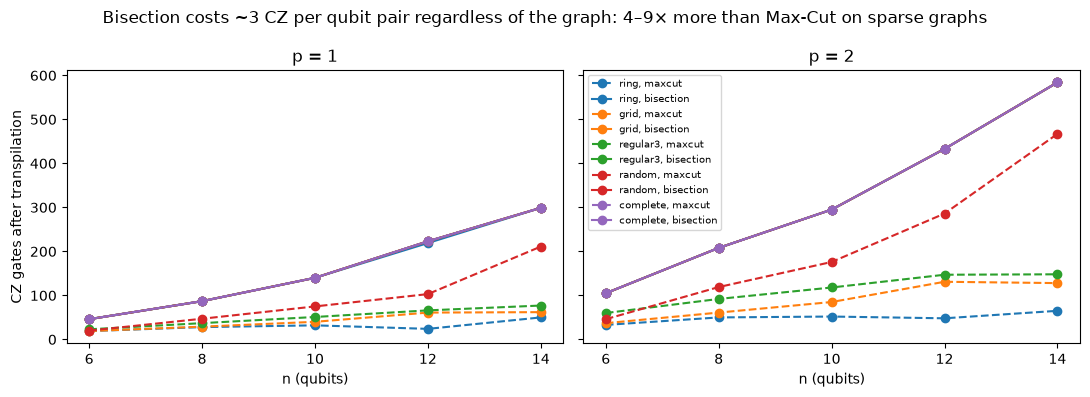

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, p in zip(axes, [1, 2]):
    part = transpilation[transpilation["p"] == p]
    for color, graph_type in zip(["C0", "C1", "C2", "C3", "C4"],
                                 ["ring", "grid", "regular3", "random", "complete"]):
        for problem, style in [("maxcut", "--"), ("bisection", "-")]:
            g = part[(part["graph_type"] == graph_type) & (part["problem"] == problem)].sort_values("n")
            ax.plot(g["n"], g["cz_count"], style, color=color, marker="o",
                    label=graph_type + ", " + problem)

    ax.set_title("p = " + str(p))
    ax.set_xlabel("n (qubits)")
    ax.set_xticks([6, 8, 10, 12, 14])

axes[0].set_ylabel("CZ gates after transpilation")
axes[1].legend(fontsize=7)
# fig.suptitle("CZ gates on ibm_boston vs. problem size")
fig.suptitle("Bisection costs ~3 CZ per qubit pair regardless of the graph: 4–9× more than Max-Cut on sparse graphs")

plt.tight_layout()
plt.savefig("../figures/cz_vs_n_ibm_boston.png", dpi=150)
plt.show()

In [10]:
for name in ["ring_10", "grid_10", "complete_10"]:
    graph = json_to_graph(find_instance(instances, name))
    H = bisection_hamiltonian(graph, generate_penalty_A(graph))
    row = [r for r in rows_warm if r["name"] == name and r["problem"] == "bisection" and r["p"] == 1][0]

    for label, hamiltonian in [("original order", H), ("sorted order", H.sort())]:
        c = build_qaoa(hamiltonian, 1).assign_parameters(row["params"])
        c.measure_all()
        t, _ = transpile_best(c, backend)
        print(name, label, "| cz:", t.count_ops().get("cz", 0))

ring_10 original order | cz: 166
ring_10 sorted order | cz: 140
grid_10 original order | cz: 194
grid_10 sorted order | cz: 140
complete_10 original order | cz: 140
complete_10 sorted order | cz: 140


Simulare pe Aer

In [11]:
from qiskit_aer import AerSimulator

noisy_simulator = AerSimulator.from_backend(backend)
print(noisy_simulator)

AerSimulator('aer_simulator_from(ibm_boston)'
             noise_model=<NoiseModel on ['measure_reset_2', 'reset_2', 'measure_reset', 'sx', 'cz', 'xslow', 'measure', 'id', 'measure_2', 'reset', 'x']>)


In [12]:
from src.classical import max_cut_bruteforce, bisection_bruteforce
from src.qaoa import qaoa_metrics
from src.hardware import counts_to_probabilities, transpile_qaoa_best

def problem_setup(name, problem):
    """Graph, Hamiltonian, optimum and optimal bitstrings for one instance and problem."""
    graph = json_to_graph(find_instance(instances, name))
    if problem == "maxcut":
        H = max_cut_hamiltonian(graph)
        optimum, optimal_bitstrings = max_cut_bruteforce(graph)
    else:
        H = bisection_hamiltonian(graph, generate_penalty_A(graph))
        optimum, optimal_bitstrings = bisection_bruteforce(graph)
    return graph, H, optimum, optimal_bitstrings

def find_row(name, problem, p):
    """The row of rows_warm with the optimized angles (and ideal metrics) for one circuit."""
    return [r for r in rows_warm if r["name"] == name and r["problem"] == problem and r["p"] == p][0]

In [13]:
name, problem, p = "ring_6", "maxcut", 1

graph, H, optimum, optimal_bitstrings = problem_setup(name, problem)
row = find_row(name, problem, p)

transpiled, seed, order = transpile_qaoa_best(H, p, row["params"], backend)

job = noisy_simulator.run(transpiled, shots=4000, seed_simulator=42)
counts = job.result().get_counts()

top = sorted(counts.items(), key=lambda item: item[1], reverse=True)[:5]
print("most frequent bitstrings:", top)

probabilities = counts_to_probabilities(counts, graph.number_of_nodes())
noisy = qaoa_metrics(graph, problem, probabilities, optimal_bitstrings)

print("ideal:", {k: round(row[k], 3) for k in ["valid_fraction", "mean_cut", "p_optimal"]})
print("noisy:", {k: round(noisy[k], 3) for k in ["valid_fraction", "mean_cut", "p_optimal"]})

most frequent bitstrings: [('101010', 558), ('010101', 543), ('001101', 153), ('010011', 150), ('010010', 142)]
ideal: {'valid_fraction': 1.0, 'mean_cut': 4.5, 'p_optimal': 0.285}
noisy: {'valid_fraction': 1.0, 'mean_cut': 4.454, 'p_optimal': 0.275}


In [14]:
selected = ["ring_6", "grid_10", "regular3_14"]
noisy_rows = []

for name in selected:
    for problem in ["maxcut", "bisection"]:
        graph, H, optimum, optimal_bitstrings = problem_setup(name, problem)

        for p in [1, 2]:
            row = find_row(name, problem, p)
            transpiled, seed, order = transpile_qaoa_best(H, p, row["params"], backend)

            counts = noisy_simulator.run(transpiled, shots=4000, seed_simulator=42).result().get_counts()
            probabilities = counts_to_probabilities(counts, graph.number_of_nodes())
            noisy = qaoa_metrics(graph, problem, probabilities, optimal_bitstrings)

            noisy_rows.append({
                "name": name,
                "graph_type": row["graph_type"],
                "n": row["n"],
                "problem": problem,
                "p": p,
                "cz_count": transpiled.count_ops().get("cz", 0),
                "esp": estimated_success(transpiled, backend),
                "optimum": optimum,
                "ideal_valid_fraction": row["valid_fraction"],
                "noisy_valid_fraction": noisy["valid_fraction"],
                "ideal_mean_cut": row["mean_cut"],
                "noisy_mean_cut": noisy["mean_cut"],
                "ideal_p_optimal": row["p_optimal"],
                "noisy_p_optimal": noisy["p_optimal"],
            })
            print(name, problem, "p =", p, "done")

noisy_results = pd.DataFrame(noisy_rows)
noisy_results.to_csv("../results/sim_noisy_ibm_boston.csv", index=False)
noisy_results

ring_6 maxcut p = 1 done
ring_6 maxcut p = 2 done
ring_6 bisection p = 1 done
ring_6 bisection p = 2 done
grid_10 maxcut p = 1 done
grid_10 maxcut p = 2 done
grid_10 bisection p = 1 done
grid_10 bisection p = 2 done
regular3_14 maxcut p = 1 done
regular3_14 maxcut p = 2 done
regular3_14 bisection p = 1 done
regular3_14 bisection p = 2 done


,name,graph_type,n,problem,p,cz_count,esp,optimum,ideal_valid_fraction,noisy_valid_fraction,ideal_mean_cut,noisy_mean_cut,ideal_p_optimal,noisy_p_optimal
0,ring_6,ring,6,maxcut,1,19,0.951839,6,1.000000,1.00000,4.500000,4.454500,0.285170,0.27525
1,ring_6,ring,6,maxcut,2,33,0.938351,6,1.000000,1.00000,5.000000,4.936500,0.536337,0.50650
2,ring_6,ring,6,bisection,1,46,0.923329,2,0.632956,0.60650,2.268502,2.302556,0.575329,0.54200
3,ring_6,ring,6,bisection,2,105,0.866761,2,0.898472,0.81150,2.301063,2.333949,0.804954,0.71625
4,grid_10,grid,10,maxcut,1,40,0.903981,13,1.000000,1.00000,9.190654,9.091000,0.084717,0.08050
5,grid_10,grid,10,maxcut,2,85,0.862762,13,1.000000,1.00000,10.659042,10.416750,0.284323,0.24800
6,grid_10,grid,10,bisection,1,140,0.805220,3,0.387902,0.38175,5.980796,6.149967,0.000136,0.00125
7,grid_10,grid,10,bisection,2,295,0.652778,3,0.623932,0.52925,6.874500,6.978271,0.000178,0.00075
8,regular3_14,regular3,14,maxcut,1,77,0.820913,17,1.000000,1.00000,13.944850,13.786250,0.039127,0.02950
9,regular3_14,regular3,14,maxcut,2,148,0.775549,17,1.000000,1.00000,15.140017,14.829000,0.162246,0.13300


Matricea de experimente

In [15]:
qpu_names = [graph_type + "_" + str(n)
             for graph_type in ["ring", "regular3", "random"]
             for n in [6, 10, 14]]

transpilation = pd.read_csv("../results/transpilation_ibm_boston.csv")
ideal = pd.read_csv("../results/sim_ideal_warm.csv")[["name", "problem", "p", "score"]]

qpu_list = transpilation[transpilation["name"].isin(qpu_names)]
qpu_list = qpu_list.merge(ideal, on=["name", "problem", "p"])
qpu_list = qpu_list[["name", "graph_type", "n", "problem", "p",
                     "cz_count", "esp", "score", "seed", "order"]]
qpu_list = qpu_list.sort_values(["n", "name", "problem", "p"]).reset_index(drop=True)

print(len(qpu_list), "circuits")
qpu_list

36 circuits


,name,graph_type,n,problem,p,cz_count,esp,score,seed,order
0,random_6,random,6,bisection,1,46,0.923329,0.088984,1,sorted
1,random_6,random,6,bisection,2,105,0.866592,-0.203170,0,sorted
2,random_6,random,6,maxcut,1,20,0.951499,0.527188,4,original
3,random_6,random,6,maxcut,2,46,0.922816,0.790121,4,original
4,regular3_6,regular3,6,bisection,1,46,0.923329,0.570191,1,sorted
5,regular3_6,regular3,6,bisection,2,105,0.866016,0.860993,0,sorted
6,regular3_6,regular3,6,maxcut,1,23,0.947443,0.575689,0,sorted
7,regular3_6,regular3,6,maxcut,2,60,0.908673,0.841180,3,original
8,ring_6,ring,6,bisection,1,46,0.923329,0.832186,1,sorted
9,ring_6,ring,6,bisection,2,105,0.866761,0.811835,0,sorted


Circuitele menite sa esueze

In [16]:
extra = []
for name in ["regular3_14", "random_14"]:
    graph, H, optimum, optimal_bitstrings = problem_setup(name, "bisection")
    row = find_row(name, "bisection", 3)
    transpiled, seed, order = transpile_qaoa_best(H, 3, row["params"], backend)
    extra.append({
        "name": name, "graph_type": row["graph_type"], "n": row["n"],
        "problem": "bisection", "p": 3,
        "cz_count": transpiled.count_ops().get("cz", 0),
        "esp": estimated_success(transpiled, backend),
        "score": ideal[(ideal["name"] == name) & (ideal["problem"] == "bisection")
                       & (ideal["p"] == 3)]["score"].iloc[0],
        "seed": seed, "order": order,
    })
    print(name, "p = 3 done")

qpu_list = pd.concat([qpu_list, pd.DataFrame(extra)], ignore_index=True)
qpu_list.tail(3)

regular3_14 p = 3 done
random_14 p = 3 done


,name,graph_type,n,problem,p,cz_count,esp,score,seed,order
35,ring_14,ring,14,maxcut,2,65,0.797429,0.666667,4,original
36,regular3_14,regular3,14,bisection,3,906,0.310190,0.020138,4,sorted
37,random_14,random,14,bisection,3,906,0.309742,-0.030575,4,sorted


In [17]:
def predict(row):
    if row["esp"] < 0.35 or row["score"] < 0.15:
        return "fail"
    if row["esp"] > 0.8 and row["score"] > 0.4:
        return "works"
    return "weak"

qpu_list["prediction"] = qpu_list.apply(predict, axis=1)
qpu_list["prediction"].value_counts()

prediction
works    18
fail     11
weak      9
Name: count, dtype: int64

In [18]:
repeat = [("ring_6", "maxcut", 1), ("regular3_10", "bisection", 1), ("random_14", "maxcut", 1)]
qpu_list["repeat"] = [(r["name"], r["problem"], r["p"]) in repeat for _, r in qpu_list.iterrows()]

In [19]:
qpu_list.to_csv("../data/qpu/circuit_list_2026-10-26.csv", index=False)